# Medical Imaging Data (DICOM): From Slices to a 3D Surface

A CT scanner does not take one 3D picture. It saves the body as a **stack of 2D cross-sections**, one file per slice, in the **DICOM** format. In this notebook we turn 68 such slices of a chest scan into a 3D model.

```
68 .dcm files ──► sort & check ──► 3D array ──► Hounsfield ──► 2D views ──► marching ──► 3D surfaces ──► OBJ file
  (one slice     (data cleaning)   (z, y, x)     Units (HU)    (axial,       cubes        (skin, bone)
   per file)                                                    sagittal)
```

| Step | What we do | Result |
|---|---|---|
| 1 | Find and read the DICOM files | 68 `Dataset` objects (header + pixels) |
| 2 | Check the slices and sort them by height | slices in the right order, bottom to top |
| 3 | Look at the header (metadata) | image size, pixel size, slice spacing |
| 4 | Stack the slices and convert to Hounsfield Units | a 68 × 512 × 512 volume in HU |
| 5 | View the volume in 2D | axial slice grid and a sagittal side view |
| 6 | Downsample and extract a bone surface | a triangle mesh (marching cubes) |
| 7 | Draw several iso-surfaces in 3D | skin, soft tissue, bone, dense bone |
| 8 | Export the bone mesh | `isoSurface.obj` |

The `README.md` in this folder explains each step in more detail.

## Setup

```sh
pip install pydicom scikit-image scipy matplotlib numpy pandas ipympl
```

- `pydicom` reads `.dcm` files
- `scikit-image` provides marching cubes (`measure.marching_cubes`)
- `scipy` provides `zoom` for downsampling

In [1]:
# ! pip install pydicom
# ! pip install scikit-image

import pandas as pd
import pydicom
import glob as glb
import numpy as np

import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

from scipy.ndimage import zoom

from skimage import measure


`%matplotlib widget` makes the plots interactive, so you can rotate the 3D plot with the mouse. If it fails in your environment, change it to `%matplotlib inline`.

In [2]:
# Interactive plots in Jupyter / VS Code (needs: pip install ipympl).
# If ipympl is not available, switch to: %matplotlib inline
%matplotlib widget

## Step 1: Find the files

The `DICOM_data/` folder holds 68 files, `01.dcm` … `68.dcm`. Each file is **one slice** of the body.

`glob` returns files in arbitrary order, so we sort the list. The names are zero-padded (`01`, `02`, …), so sorting them as text gives the right order.

In [3]:
dicom_folder = './DICOM_data/*.dcm'
# glob returns files in arbitrary order -> sort them (zero-padded names: 01.dcm, 02.dcm, ...)
files = sorted(glb.glob(dicom_folder))
print(f'Found {len(files)} DICOM files')
assert len(files) > 0, f'No DICOM files found in {dicom_folder}'

Found 68 DICOM files


## Step 2: Read every file and check that the slices belong together

`pydicom.dcmread` returns a `Dataset` with two parts: the **header** (hundreds of named fields) and the **pixel data** (the 2D image).

Before stacking the slices into one volume, we clean the data:

1. **Same series:** all files come from the same scan (`SeriesInstanceUID`).
2. **Same size:** all slices have the same number of rows and columns.
3. **Sort by physical height:** file names are only labels. The real position of a slice is `ImagePositionPatient[2]` (z, in mm). In this dataset the file numbers count *downward*, so trusting the names would put the body upside down.
4. **Even spacing:** the gaps between slices should all be the same (5 mm). A larger gap means a slice is missing.

**Expected output:** z from 341.5 mm (bottom, upper abdomen) to 676.5 mm (top, shoulders), with a spacing of 5.00 mm everywhere.

In [4]:
# Read ALL files (do not skip any)
dicom_datasets = [pydicom.dcmread(file) for file in files]

# --- Sanity checks -------------------------------------------------------
# 1) All slices should come from the same scan series
series = {ds.SeriesInstanceUID for ds in dicom_datasets}
assert len(series) == 1, f'Files come from {len(series)} different series!'

# 2) All slices should have the same image size
shapes = {(int(ds.Rows), int(ds.Columns)) for ds in dicom_datasets}
assert len(shapes) == 1, f'Slices have different sizes: {shapes}'

# 3) Order the slices by their physical position along the body (z, in mm).
#    File names are just labels; ImagePositionPatient[2] is the real height of each slice.
#    Sorting by increasing z puts slice 0 at the bottom (feet side) and the last slice at the top (head side).
z_from_files = [float(ds.ImagePositionPatient[2]) for ds in dicom_datasets]
if z_from_files not in (sorted(z_from_files), sorted(z_from_files, reverse=True)):
    print('WARNING: file-name order does not match slice position')
dicom_datasets.sort(key=lambda ds: float(ds.ImagePositionPatient[2]))
z_positions = [float(ds.ImagePositionPatient[2]) for ds in dicom_datasets]
print(f'z range: {z_positions[0]} mm (bottom) to {z_positions[-1]} mm (top)')

# 4) Slices should be evenly spaced (no missing slices)
gaps = np.abs(np.diff(z_positions))
print(f'Slice spacing: min={gaps.min():.2f} mm, max={gaps.max():.2f} mm')
if not np.allclose(gaps, gaps[0]):
    print('WARNING: uneven slice spacing -> some slices may be missing')

z range: 341.5 mm (bottom) to 676.5 mm (top)
Slice spacing: min=5.00 mm, max=5.00 mm


## Step 3: Look at the header (metadata)

Displaying a `Dataset` lists all its header fields. The ones we use:

| Field | Value here | Meaning |
|---|---|---|
| `Rows`, `Columns` | 512, 512 | Image size in pixels |
| `PixelSpacing` | 0.736 mm × 0.736 mm | Physical size of one pixel |
| `SliceThickness` | 5.0 mm | Thickness of each slice |
| `ImagePositionPatient` | `[x, y, z]` in mm | Where the slice is in the body |
| `RescaleSlope`, `RescaleIntercept` | 1.0, −1024 | How to convert pixel values to Hounsfield Units |

> **Privacy note:** real DICOM headers can contain the patient's name, birth date and hospital IDs. Medical data must be de-identified before it is shared.

In [5]:
# Inspect the header (metadata) of one slice
dataset = dicom_datasets[0]
dataset

Dataset.file_meta -------------------------------
(0002,0000) File Meta Information Group Length  UL: 222
(0002,0001) File Meta Information Version       OB: b'\x00\x01'
(0002,0002) Media Storage SOP Class UID         UI: CT Image Storage
(0002,0003) Media Storage SOP Instance UID      UI: 1.3.12.2.1107.5.1.4.93764.30000020032604322280800012654
(0002,0010) Transfer Syntax UID                 UI: Explicit VR Little Endian
(0002,0012) Implementation Class UID            UI: 1.2.276.0.7230010.3.0.3.6.0
(0002,0013) Implementation Version Name         SH: 'OFFIS_DCMTK_360'
(0002,0016) Source Application Entity Title     AE: 'AN_CTAWP93764'
-------------------------------------------------
(0008,0005) Specific Character Set              CS: 'ISO_IR 100'
(0008,0008) Image Type                          CS: ['ORIGINAL', 'PRIMARY', 'AXIAL', 'CT_SOM5 SPI']
(0008,0016) SOP Class UID                       UI: CT Image Storage
(0008,0018) SOP Instance UID                    UI: 1.3.12.2.1107.5.1.4.9

## Step 4: Build the 3D volume in Hounsfield Units

We stack the sorted slices into one NumPy array `ct_scan[z, y, x]`:

```
   slice 67 (top)    ┌───────┐         ┌───────┐
   ...               │       │   ──►  ┌┴──────┐│   shape = (68, 512, 512)
   slice 0 (bottom)  └───────┘       ┌┴──────┐││          (z,   y,   x)
                      512×512        └───────┘┘┘
```

At the same time we convert the stored pixel values to **Hounsfield Units (HU)**, the physical CT scale:

```
HU = raw_value × RescaleSlope + RescaleIntercept      (here: raw − 1024)
```

| Tissue | Approximate HU |
|---|---|
| Air | −1000 |
| Lung | −900 to −500 |
| Fat | −100 to −50 |
| Water | 0 |
| Soft tissue | +20 to +80 |
| Bone | +300 and above |

We also record the **voxel size**. A voxel (3D pixel) here is **5 mm tall but only 0.736 mm wide**, so it is not a cube. We use these spacings in every plot so the body keeps its real proportions.

In [6]:
rows = int(dataset.Rows)
columns = int(dataset.Columns)

# Physical voxel size in mm: (z, y, x). Voxels are NOT cubes!
slice_spacing = float(np.abs(np.diff(z_positions)).mean())   # distance between slices
pixel_spacing_y, pixel_spacing_x = map(float, dataset.PixelSpacing)
voxel_spacing = (slice_spacing, pixel_spacing_y, pixel_spacing_x)
print('Voxel spacing (z, y, x) in mm:', voxel_spacing)

# Build the 3D volume and convert raw pixel values to Hounsfield Units (HU):
#   HU = raw * RescaleSlope + RescaleIntercept
# (air ~ -1000, water = 0, soft tissue ~ 20-80, bone ~ 300+)
ct_scan = np.zeros((len(dicom_datasets), rows, columns), dtype=np.float32)
for i, ds in enumerate(dicom_datasets):
    ct_scan[i, :, :] = ds.pixel_array * float(ds.RescaleSlope) + float(ds.RescaleIntercept)

print('Volume shape (z, y, x):', ct_scan.shape)
print(f'HU range: {ct_scan.min():.0f} to {ct_scan.max():.0f}')

Voxel spacing (z, y, x) in mm: (5.0, 0.736328125, 0.736328125)
Volume shape (z, y, x): (68, 512, 512)
HU range: -1024 to 1621


## Step 5: Look at the volume in 2D

Indexing the 3D array in different ways gives the three standard medical views:

| Code | View | Looks at the body from |
|---|---|---|
| `ct_scan[k, :, :]` | **Axial** | above/below (the original slices) |
| `ct_scan[:, :, c]` | **Sagittal** | the side |
| `ct_scan[:, r, :]` | **Coronal** | the front |

`vmin=-1000, vmax=1000` sets the **window**: HU values below −1000 are black and values above 1000 are white.

### Axial slices

The first 50 slices, from the bottom of the volume upward.

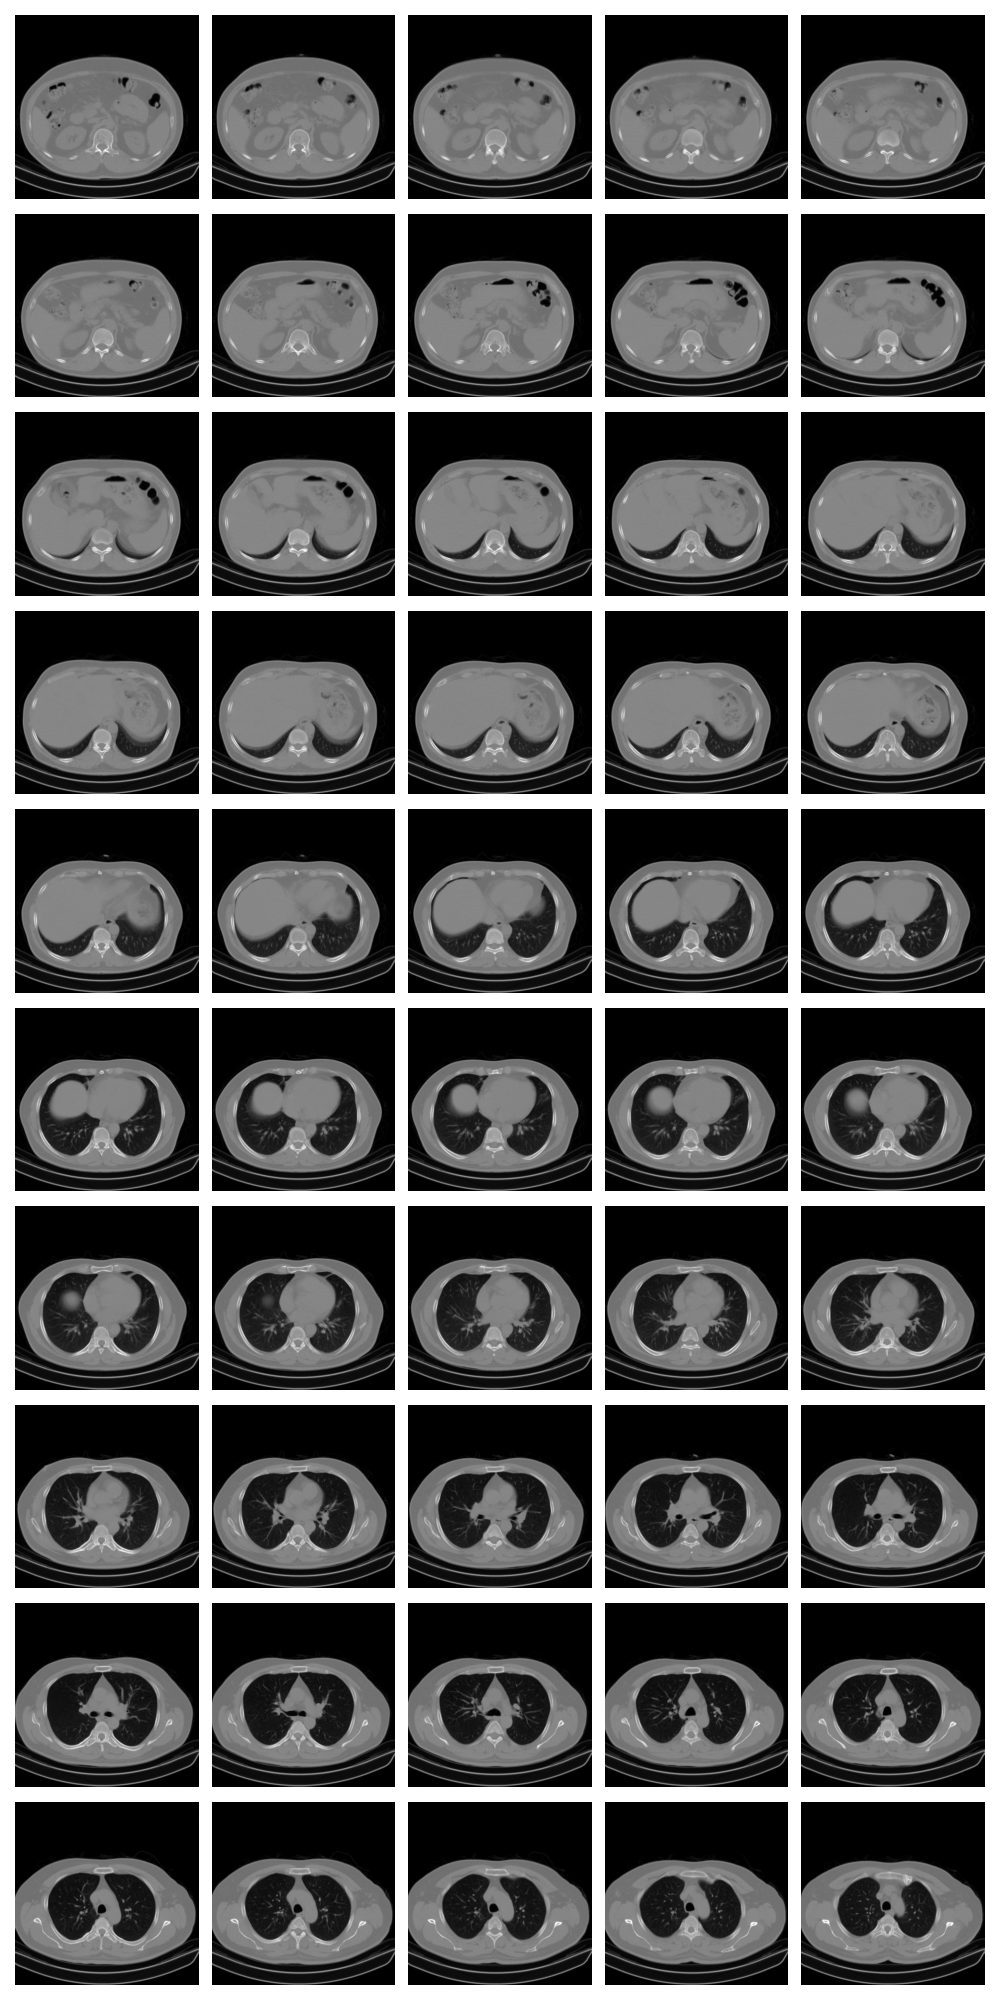

In [7]:
f, ax = plt.subplots(10, 5, figsize=(10, 20))
axs = ax.ravel()
for i in range(min(10*5, ct_scan.shape[0])):
    axs[i].imshow(ct_scan[i, :, :], cmap='gray', vmin=-1000, vmax=1000)
for a in axs:
    a.axis('off')
plt.tight_layout()

**What you should see:** reading left to right and top to bottom, the slices move up the body, from the upper abdomen (liver, kidneys, bowel gas) through the heart to the upper chest. Air is black, soft tissue is grey and bone is white. The curved lines under the body are the scanner table.

### Sagittal side view

We take column 100 from every slice and stack them, which shows the body from the side. `extent` gives both axes in millimetres. Without it, each 5 mm slice would be drawn as one pixel row and the body would look squashed to about 1/7 of its height.

Text(0, 0.5, 'z (mm)')

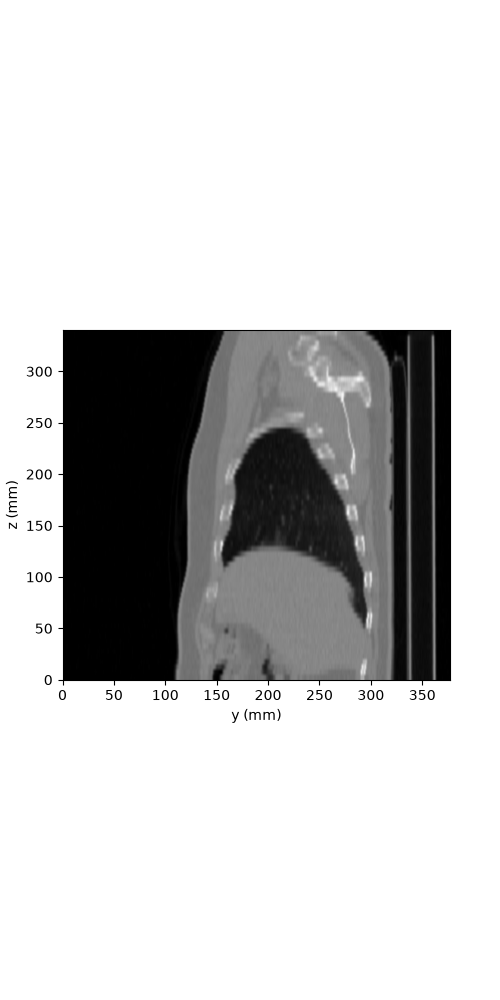

In [8]:
# Side view: use the real physical size (mm) so the anatomy is not squashed
f, ax = plt.subplots(1, 1, figsize=(5, 10))
ax.imshow(ct_scan[:, :, 100], cmap='gray', vmin=-1000, vmax=1000,
          origin='lower',
          extent=[0, rows * pixel_spacing_y, 0, ct_scan.shape[0] * slice_spacing])
ax.set_xlabel('y (mm)')
ax.set_ylabel('z (mm)')

**What you should see:** the lungs (black), the diaphragm and liver below them, the spine on the right (the patient's back) and the shoulder bones at the top.

## Step 6: Extract a bone surface with Marching Cubes

An **iso-surface** is the 3D version of a contour line: the surface where the data crosses one value (the *iso-value*). The **marching cubes** algorithm finds it by looking at every small cube of 8 neighbouring voxels. If some corners are above the iso-value and some are below, it places triangles inside that cube. All the triangles together form a **mesh**.

Two preparation steps:

- **Downsample:** 68 × 512 × 512 ≈ 18 million voxels is slow, so we shrink each slice by 3 in x and y. We keep every slice in z, because there are only 68 and they are already 5 mm apart.
- **Spacing:** we pass `spacing=` so the vertex positions come out in millimetres.

We use **300 HU** as the iso-value, which is the boundary of bone.

In [9]:
# Downsample in-plane only: we have few slices (thick 5 mm), so keep every slice in z
downsampling_factor = 3
downsized_ct_scan = zoom(ct_scan, (1, 1 / downsampling_factor, 1 / downsampling_factor))

# Spacing of the downsized volume in mm (z, y, x)
downsized_spacing = (voxel_spacing[0],
                     voxel_spacing[1] * downsampling_factor,
                     voxel_spacing[2] * downsampling_factor)

# Iso-value in Hounsfield Units: ~300 HU extracts bone
bone_iso_value = 300  # Adjust as needed

# Extract iso-surface using marching cubes (vertices are in mm thanks to `spacing`)
bone_verts, bone_faces, _, _ = measure.marching_cubes(downsized_ct_scan, bone_iso_value,
                                                      spacing=downsized_spacing)
print(f'Bone surface: {len(bone_verts)} vertices, {len(bone_faces)} faces')

Bone surface: 78794 vertices, 156548 faces


## Step 7: Several iso-surfaces in one 3D plot

Different iso-values reveal different tissues:

| Iso-value | Shows | Colour |
|---|---|---|
| −300 HU | Skin (boundary between air and body) | orange |
| 0 HU | Soft tissue and organs | red |
| 300 HU | Bone | blue |
| 700 HU | Dense bone only | green |

The outer surfaces are drawn more transparent so the skeleton inside stays visible. `marching_cubes` returns vertices as `(z, y, x)`, so we reverse them to `(x, y, z)` to make z point up. `set_box_aspect` keeps the real physical proportions.

/Users/amirakhavan/Documents/Projects/University/CIS-568/DataViz-Fall2026/.venv/lib/python3.14/site-packages/ipympl/backend_nbagg.py:392: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  self.figure.savefig(buf, format='png', dpi='figure')


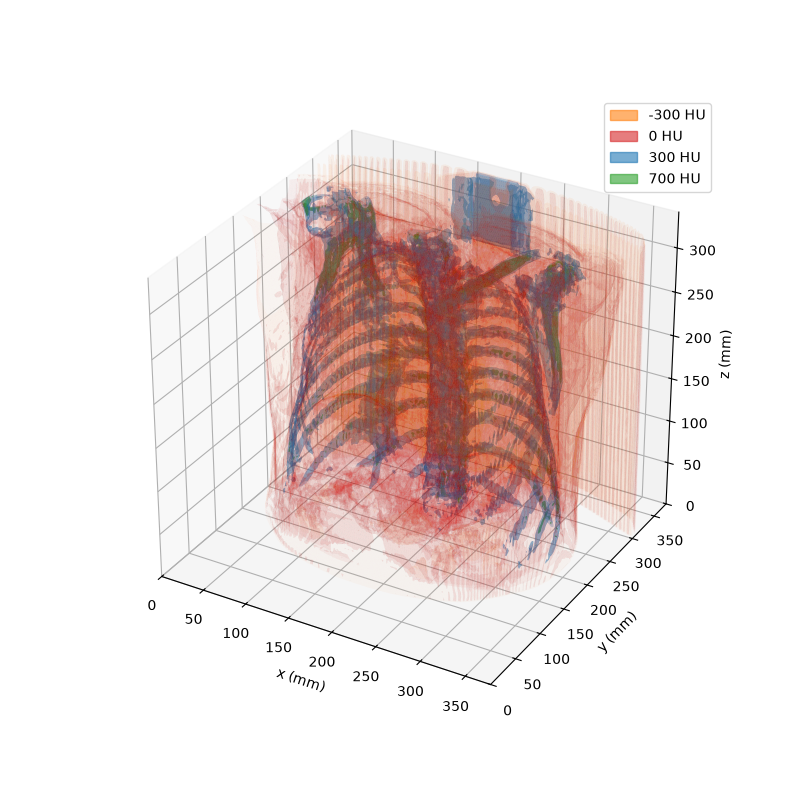

In [10]:
# Several iso-surfaces in HU: skin -> soft tissue -> bone -> dense bone
threshold_values = [-300, 0, 300, 700]
colors = ['tab:orange', 'tab:red', 'tab:blue', 'tab:green']
alphas = [0.03, 0.05, 0.3, 0.6]   # outer surfaces more transparent so inner ones show

# Store each surface separately (do NOT overwrite bone_verts / bone_faces)
surfaces = {}
for iso_value in threshold_values:
    v, f_, _, _ = measure.marching_cubes(downsized_ct_scan, iso_value, spacing=downsized_spacing)
    surfaces[iso_value] = (v, f_)

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')

from matplotlib.patches import Patch
for (iso_value, (v, f_)), color, alpha in zip(surfaces.items(), colors, alphas):
    v_xyz = v[:, ::-1]   # marching_cubes returns (z, y, x) -> reorder to (x, y, z) so z points up
    mesh = Poly3DCollection(v_xyz[f_], alpha=alpha, facecolors=color, linewidths=0)
    ax.add_collection3d(mesh)

# add_collection3d does not rescale the axes -> set limits to the volume size (mm)
extent_mm = (np.array(downsized_ct_scan.shape) * np.array(downsized_spacing))[::-1]  # (x, y, z)
ax.set_xlim(0, extent_mm[0]); ax.set_ylim(0, extent_mm[1]); ax.set_zlim(0, extent_mm[2])
ax.set_box_aspect(extent_mm)   # true physical proportions

ax.set_xlabel('x (mm)')
ax.set_ylabel('y (mm)')
ax.set_zlabel('z (mm)')
ax.legend(handles=[Patch(color=c, alpha=0.6, label=f'{t} HU') for t, c in zip(threshold_values, colors)])
plt.show()

**What you should see:** the rib cage, spine, collarbones and shoulder blades inside the faint skin and soft-tissue surfaces. With `%matplotlib widget` you can drag to rotate the plot. The rectangular block behind the body is part of the scanner table.

## Step 8: Export the bone mesh to an OBJ file

**OBJ** is a simple text format for 3D meshes that most 3D tools can open:

```
v 12.5 140.2 88.0      ← a vertex (x y z)
f 1 2 3                ← a triangle made of vertices 1, 2 and 3
```

OBJ numbers vertices from **1**, while Python counts from **0**, so we add 1 to every face index.

In [11]:
# Export the BONE surface (from the marching-cubes step above) to an OBJ file
obj_filename = 'isoSurface.obj'  # Replace with your desired file path
verts, faces = bone_verts, bone_faces

with open(obj_filename, 'w') as obj_file:
    # Write vertices (in mm)
    for vertex in verts:
        obj_file.write(f'v {vertex[0]} {vertex[1]} {vertex[2]}\n')
    # Write faces (OBJ indices are 1-based)
    for face in faces:
        obj_file.write(f'f {face[0]+1} {face[1]+1} {face[2]+1}\n')

print(f'Mesh ({bone_iso_value} HU) exported to {obj_filename}')

Mesh (300 HU) exported to isoSurface.obj


## Summary

We went from 68 separate image files to a 3D model:

1. **Read and cleaned** the slices: one series, one image size, sorted by physical height, no missing slices.
2. **Stacked** them into a 68 × 512 × 512 volume and converted the values to **Hounsfield Units**, so thresholds mean real tissues.
3. **Viewed** the volume as axial slices and a sagittal side view, using the real voxel size (5 × 0.736 × 0.736 mm).
4. **Extracted iso-surfaces** with marching cubes: skin (−300 HU), soft tissue (0 HU), bone (300 HU) and dense bone (700 HU).
5. **Exported** the bone surface to `isoSurface.obj`, which you can open in Blender, macOS Preview, Windows 3D Viewer or three.js.
6. **ThreeJS** in the upcoming weeks we will load this data using ThreeJS and visualize it with sliders to review the output.